In [206]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Task 1

In [207]:
filepath = '/content/drive/MyDrive/DSA/Exit Test/G2 (1).csv'
df = pd.read_csv(filepath)
df

,id,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense
0,1,bulbasaur,7,69,64.0,grass,poison,45,49,49
1,2,ivysaur,10,130,142.0,grass,poison,60,62,63
2,3,venusaur,20,1000,236.0,grass,poison,80,82,83
3,4,charmander,6,85,62.0,fire,NaN,39,52,43
4,5,charmeleon,11,190,142.0,fire,NaN,58,64,58
...,...,...,...,...,...,...,...,...,...,...
1346,10322,tatsugiri-curly-mega,6,240,NaN,dragon,water,68,65,90
1347,10323,tatsugiri-droopy-mega,6,240,NaN,dragon,water,68,65,90
1348,10324,tatsugiri-stretchy-mega,6,240,NaN,dragon,water,68,65,90
1349,10325,baxcalibur-mega,21,3150,NaN,dragon,ice,115,175,117


In [208]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1351 non-null   int64  
 1   name             1351 non-null   object 
 2   height_dm        1351 non-null   int64  
 3   weight_hg        1351 non-null   int64  
 4   base_experience  1302 non-null   float64
 5   type_1           1351 non-null   object 
 6   type_2           765 non-null    object 
 7   hp               1351 non-null   int64  
 8   attack           1351 non-null   int64  
 9   defense          1351 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 105.7+ KB


In [209]:
df.shape

(1351, 10)

In [210]:
df.describe()

,id,height_dm,weight_hg,base_experience,hp,attack,defense
count,1351.000000,1351.000000,1351.000000,1302.000000,1351.000000,1351.000000,1351.000000
mean,2841.692080,20.443375,991.059956,161.943932,71.673575,82.757957,76.193930
std,4139.019112,53.238467,1953.115812,82.532554,26.827529,32.351906,30.712902
min,1.000000,1.000000,0.000000,36.000000,1.000000,5.000000,5.000000
25%,338.500000,6.000000,94.500000,71.000000,55.000000,60.000000,55.000000
50%,676.000000,11.000000,326.000000,165.000000,70.000000,80.000000,70.000000
75%,1013.500000,17.000000,853.500000,222.500000,85.000000,102.500000,95.000000
max,10326.000000,1000.000000,10000.000000,608.000000,255.000000,190.000000,250.000000


In [211]:
df.isnull().sum()

,0
id,0
name,0
height_dm,0
weight_hg,0
base_experience,49
type_1,0
type_2,586
hp,0
attack,0
defense,0


In [212]:
df.duplicated().sum()

np.int64(0)

In [213]:
df_clean = df.copy()
df_clean

,id,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense
0,1,bulbasaur,7,69,64.0,grass,poison,45,49,49
1,2,ivysaur,10,130,142.0,grass,poison,60,62,63
2,3,venusaur,20,1000,236.0,grass,poison,80,82,83
3,4,charmander,6,85,62.0,fire,NaN,39,52,43
4,5,charmeleon,11,190,142.0,fire,NaN,58,64,58
...,...,...,...,...,...,...,...,...,...,...
1346,10322,tatsugiri-curly-mega,6,240,NaN,dragon,water,68,65,90
1347,10323,tatsugiri-droopy-mega,6,240,NaN,dragon,water,68,65,90
1348,10324,tatsugiri-stretchy-mega,6,240,NaN,dragon,water,68,65,90
1349,10325,baxcalibur-mega,21,3150,NaN,dragon,ice,115,175,117


In [214]:
df['name'].value_counts()

,count
name,
bulbasaur,1
ivysaur,1
venusaur,1
charmander,1
charmeleon,1
...,...
tatsugiri-curly-mega,1
tatsugiri-droopy-mega,1
tatsugiri-stretchy-mega,1


In [215]:
#dropping id and name columns
df_clean.drop(['id', 'name'], axis=1, inplace=True)
df_clean

,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense
0,7,69,64.0,grass,poison,45,49,49
1,10,130,142.0,grass,poison,60,62,63
2,20,1000,236.0,grass,poison,80,82,83
3,6,85,62.0,fire,NaN,39,52,43
4,11,190,142.0,fire,NaN,58,64,58
...,...,...,...,...,...,...,...,...
1346,6,240,NaN,dragon,water,68,65,90
1347,6,240,NaN,dragon,water,68,65,90
1348,6,240,NaN,dragon,water,68,65,90
1349,21,3150,NaN,dragon,ice,115,175,117


In [216]:
df['type_1'].value_counts()

,count
type_1,
water,160
normal,139
grass,122
electric,100
bug,95
psychic,86
fire,84
rock,83
dark,63


In [217]:
df['type_2'].value_counts()

,count
type_2,
flying,141
dragon,58
psychic,56
poison,54
fairy,53
steel,47
fighting,47
ground,46
ghost,44


In [218]:
df['type_1'].value_counts()

,count
type_1,
water,160
normal,139
grass,122
electric,100
bug,95
psychic,86
fire,84
rock,83
dark,63


In [219]:
#classifying numerical and categorical features in df_clean
numerical_features = df_clean.select_dtypes(include=['int64', 'float64']).columns
categorical_features = df_clean.select_dtypes(include=['object']).columns
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: Index(['height_dm', 'weight_hg', 'base_experience', 'hp', 'attack', 'defense'], dtype='object')
Categorical features: Index(['type_1', 'type_2'], dtype='object')


/tmp/ipykernel_1626/227572585.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='base_experience', y='attack', data=df_clean, palette='viridis')


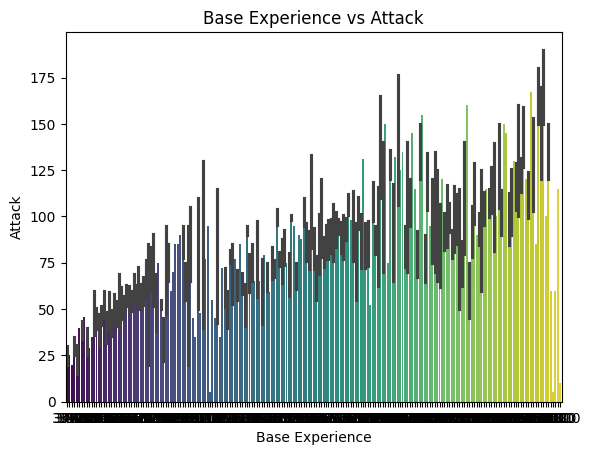

In [220]:
#base experience vs attack
sns.barplot(x='base_experience', y='attack', data=df_clean, palette='viridis')
plt.title('Base Experience vs Attack')
plt.xlabel('Base Experience')
plt.ylabel('Attack')
plt.show()

/tmp/ipykernel_1626/260511220.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='type_2', data=df_clean, palette='viridis')


Text(0.5, 0, 'Type_2')

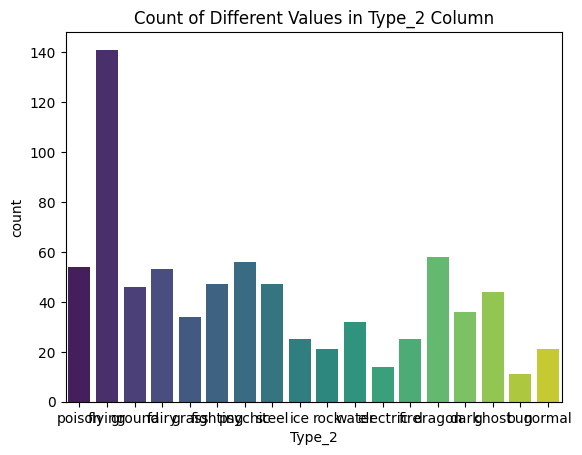

In [221]:
sns.countplot(x='type_2', data=df_clean, palette='viridis')
plt.title('Count of Different Values in Type_2 Column')
plt.xlabel('Type_2')

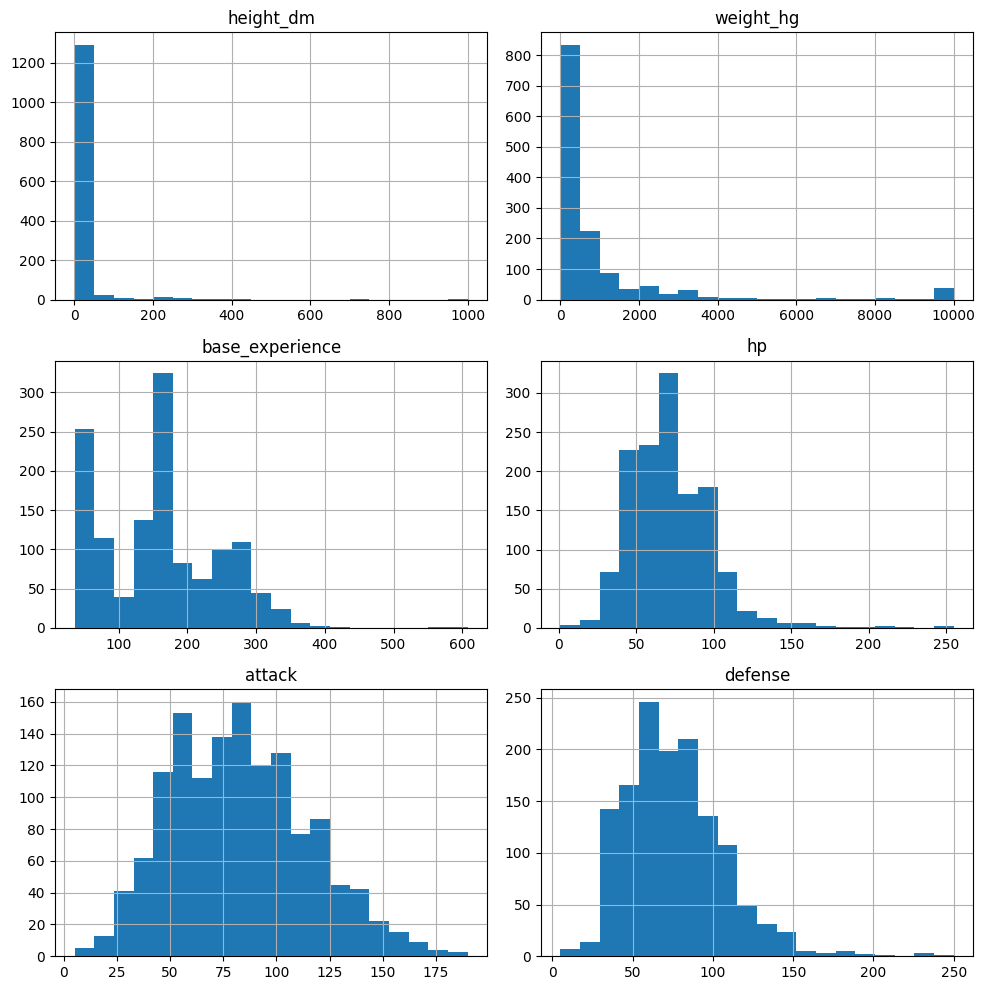

In [222]:
df_clean[numerical_features].hist(figsize=(10, 10), bins=20)
plt.tight_layout()
plt.show()

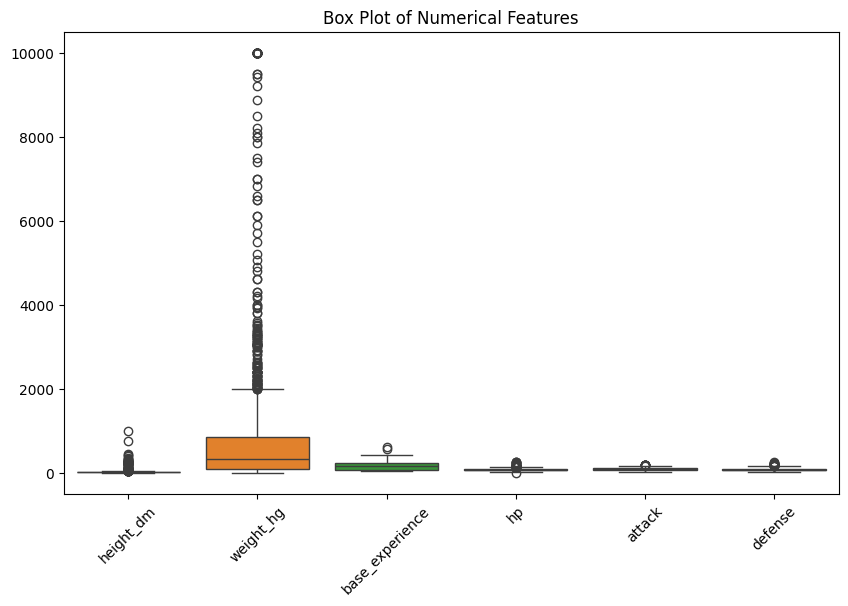

In [223]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean[numerical_features])
plt.title('Box Plot of Numerical Features')
plt.xticks(rotation=45)
plt.show()

Analytical questions

1.water in type1, and flying in type_2

2.height

3.the dataset contains 1351 rows and 10 columns in which two columns are completely unique values , hence dropped. type_1 is our target column. It has one categorical feature and 6 numerical features. most of the numerical columns are skewed

# TASK 2

In [224]:
df_clean.isna().sum()

,0
height_dm,0
weight_hg,0
base_experience,49
type_1,0
type_2,586
hp,0
attack,0
defense,0


In [225]:
df_clean['base_experience'].fillna(df_clean['base_experience'].median(), inplace=True)

/tmp/ipykernel_1626/471470810.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['base_experience'].fillna(df_clean['base_experience'].median(), inplace=True)


In [226]:
df_clean['type_2'].fillna('unknown', inplace=True)

/tmp/ipykernel_1626/3498878960.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['type_2'].fillna('unknown', inplace=True)


In [227]:
df_clean.isna().sum()

,0
height_dm,0
weight_hg,0
base_experience,0
type_1,0
type_2,0
hp,0
attack,0
defense,0


In [228]:
df_clean.head()

,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense
0,7,69,64.0,grass,poison,45,49,49
1,10,130,142.0,grass,poison,60,62,63
2,20,1000,236.0,grass,poison,80,82,83
3,6,85,62.0,fire,unknown,39,52,43
4,11,190,142.0,fire,unknown,58,64,58


In [229]:
df_clean['type_2'].value_counts()

,count
type_2,
unknown,586
flying,141
dragon,58
psychic,56
poison,54
fairy,53
steel,47
fighting,47
ground,46


In [230]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler


In [231]:
X = df_clean.drop('type_1', axis=1)
y = df_clean['type_1']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [241]:
# One-hot encode the categorical column 'type_2' before scaling
X_train_encoded = pd.get_dummies(X_train, columns=['type_2'])
X_test_encoded = pd.get_dummies(X_test, columns=['type_2'])

# Align columns of train and test sets in case some categories are missing in either
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# Initialize and fit the MinMaxScaler
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

Analytical Questions

1.without preprocessing the values can feed wrong information to the model. for example if there are missing values and we dont handle it the machine will learn biased data that could cause wrong prediction.

2.I replaced the missing spaces with 'unknown', because almost half of the data are missing , so we cant just replace it using mode value.

# TASK 3

/tmp/ipykernel_1626/278111983.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='attack', y='defense', data=df_clean, palette='viridis')


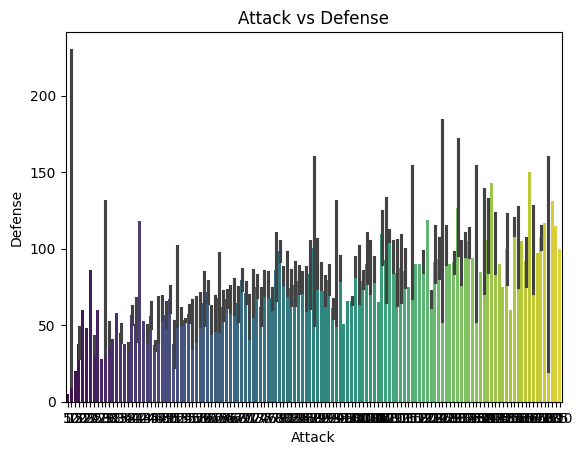

In [233]:
sns.barplot(x='attack', y='defense', data=df_clean, palette='viridis')
plt.title('Attack vs Defense')
plt.xlabel('Attack')
plt.ylabel('Defense')
plt.show()

/tmp/ipykernel_1626/983377418.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='type_1', y='hp', data=df_clean, palette='viridis')


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17],
 [Text(0, 0, 'grass'),
  Text(1, 0, 'fire'),
  Text(2, 0, 'water'),
  Text(3, 0, 'bug'),
  Text(4, 0, 'normal'),
  Text(5, 0, 'poison'),
  Text(6, 0, 'electric'),
  Text(7, 0, 'ground'),
  Text(8, 0, 'fairy'),
  Text(9, 0, 'fighting'),
  Text(10, 0, 'psychic'),
  Text(11, 0, 'rock'),
  Text(12, 0, 'ghost'),
  Text(13, 0, 'ice'),
  Text(14, 0, 'dragon'),
  Text(15, 0, 'dark'),
  Text(16, 0, 'steel'),
  Text(17, 0, 'flying')])

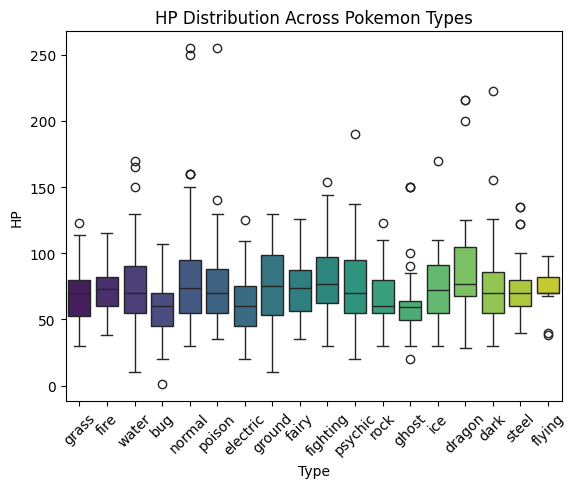

In [234]:
sns.boxplot(x='type_1', y='hp', data=df_clean, palette='viridis')
plt.title('HP Distribution Across Pokemon Types')
plt.xlabel('Type')
plt.ylabel('HP')
plt.xticks(rotation=45)

/tmp/ipykernel_1626/3647594443.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='type_1', y='base_experience', data=df_clean, palette='viridis')


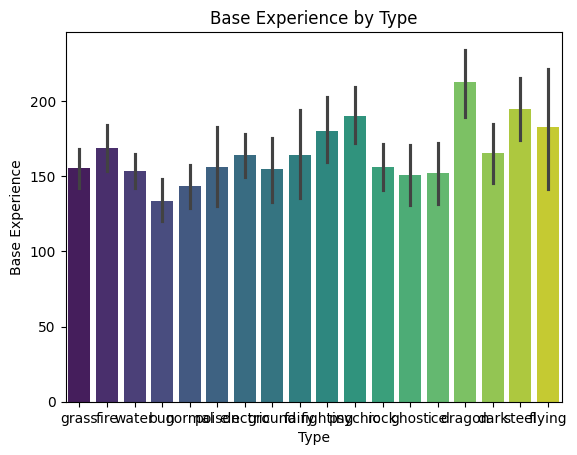

In [235]:
sns.barplot(x='type_1', y='base_experience', data=df_clean, palette='viridis')
plt.title('Base Experience by Type')
plt.xlabel('Type')
plt.ylabel('Base Experience')
plt.show()


/tmp/ipykernel_1626/3480510939.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x='height_dm', y='weight_hg', data=df_clean, palette='viridis')


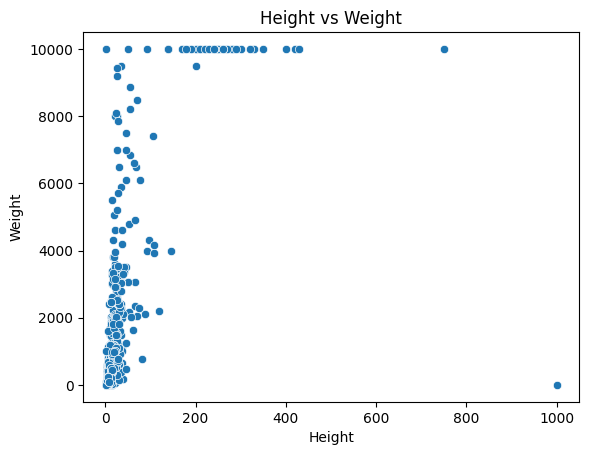

In [236]:
sns.scatterplot(x='height_dm', y='weight_hg', data=df_clean, palette='viridis')
plt.title('Height vs Weight')
plt.xlabel('Height')
plt.ylabel('Weight')
plt.show()

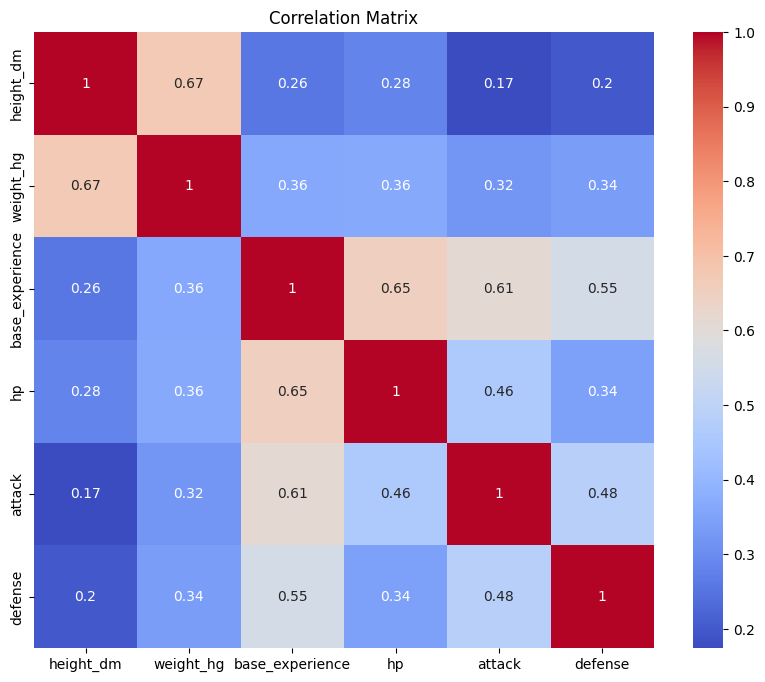

In [237]:
#correlation matrix betweeen numerical columns with type 1 column
correlation_matrix = df_clean[numerical_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

Analytical Questions

1.'fighting'

2.height and weight are not necesarilt related , though there are some relation between values

3.base experience

In [238]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [243]:
lr = LogisticRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Logistic Regression Classification Report:\n", classification_report(y_test, y_pred_lr))
print("Logistic Regression Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.14391143911439114
Logistic Regression Classification Report:
               precision    recall  f1-score   support

         bug       0.00      0.00      0.00        21
        dark       0.00      0.00      0.00        16
      dragon       0.12      0.08      0.10        12
    electric       0.29      0.17      0.21        12
       fairy       0.00      0.00      0.00         8
    fighting       0.00      0.00      0.00        18
        fire       0.00      0.00      0.00        22
      flying       0.00      0.00      0.00         1
       ghost       0.40      0.25      0.31         8
       grass       0.19      0.21      0.20        24
      ground       0.00      0.00      0.00        12
         ice       0.00      0.00      0.00        12
      normal       0.17      0.68      0.28        22
      poison       0.00      0.00      0.00        10
     psychic       0.10      0.06      0.07        18
        rock       0.07      0.07      0.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [244]:
dt = DecisionTreeClassifier()
dt.fit(X_train_scaled, y_train)
y_pred_dt = dt.predict(X_test_scaled)
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Decision Tree Classification Report:\n", classification_report(y_test, y_pred_dt))
print("Decision Tree Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

Decision Tree Accuracy: 0.2140221402214022
Decision Tree Classification Report:
               precision    recall  f1-score   support

         bug       0.19      0.14      0.16        21
        dark       0.10      0.06      0.08        16
      dragon       0.25      0.25      0.25        12
    electric       0.38      0.50      0.43        12
       fairy       0.00      0.00      0.00         8
    fighting       0.26      0.33      0.29        18
        fire       0.08      0.05      0.06        22
      flying       0.00      0.00      0.00         1
       ghost       0.25      0.25      0.25         8
       grass       0.25      0.33      0.29        24
      ground       0.11      0.08      0.10        12
         ice       0.22      0.17      0.19        12
      normal       0.14      0.27      0.19        22
      poison       0.10      0.10      0.10        10
     psychic       0.29      0.28      0.29        18
        rock       0.25      0.36      0.29        14


In [245]:
#fit random forest classifier
rf = RandomForestClassifier()
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Random Forest Classification Report:\n", classification_report(y_test, y_pred_rf))
print("Random Forest Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 0.2878228782287823
Random Forest Classification Report:
               precision    recall  f1-score   support

         bug       0.25      0.33      0.29        21
        dark       0.25      0.12      0.17        16
      dragon       0.43      0.50      0.46        12
    electric       0.25      0.33      0.29        12
       fairy       0.00      0.00      0.00         8
    fighting       0.42      0.28      0.33        18
        fire       0.17      0.14      0.15        22
      flying       0.00      0.00      0.00         1
       ghost       0.30      0.38      0.33         8
       grass       0.31      0.33      0.32        24
      ground       0.40      0.17      0.24        12
         ice       0.75      0.25      0.38        12
      normal       0.18      0.41      0.25        22
      poison       0.33      0.10      0.15        10
     psychic       0.56      0.28      0.37        18
        rock       0.47      0.50      0.48        14


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [247]:
SVC_model = SVC()
SVC_model.fit(X_train_scaled, y_train)
y_pred_SVC = SVC_model.predict(X_test_scaled)
print("SVC Accuracy:", accuracy_score(y_test, y_pred_SVC))
print("SVC Classification Report:\n", classification_report(y_test, y_pred_SVC))
print("SVC Confusion Matrix:\n", confusion_matrix(y_test, y_pred_SVC))

SVC Accuracy: 0.16605166051660517
SVC Classification Report:
               precision    recall  f1-score   support

         bug       0.24      0.19      0.21        21
        dark       0.00      0.00      0.00        16
      dragon       0.25      0.17      0.20        12
    electric       1.00      0.08      0.15        12
       fairy       0.00      0.00      0.00         8
    fighting       0.00      0.00      0.00        18
        fire       0.11      0.09      0.10        22
      flying       0.00      0.00      0.00         1
       ghost       0.40      0.25      0.31         8
       grass       0.20      0.21      0.20        24
      ground       0.00      0.00      0.00        12
         ice       0.00      0.00      0.00        12
      normal       0.15      0.41      0.22        22
      poison       0.00      0.00      0.00        10
     psychic       0.12      0.06      0.08        18
        rock       0.00      0.00      0.00        14
       steel       

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [248]:
#fine tuning random forest model using randomised search cv
from sklearn.model_selection import RandomizedSearchCV
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10]
}
random_search = RandomizedSearchCV(estimator=rf, param_distributions=param_grid, n_iter=10, cv=5, n_jobs=-1, verbose=2, random_state=42)
random_search.fit(X_train_scaled, y_train)
best_params = random_search.best_params_
best_rf = RandomForestClassifier(**best_params)
best_rf.fit(X_train_scaled, y_train)
y_pred_best_rf = best_rf.predict(X_test_scaled)
print("Best Random Forest Accuracy:", accuracy_score(y_test, y_pred_best_rf))
print("Best Random Forest Classification Report:\n", classification_report(y_test, y_pred_best_rf))
print("Best Random Forest Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best_rf))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Random Forest Accuracy: 0.28413284132841327
Best Random Forest Classification Report:
               precision    recall  f1-score   support

         bug       0.29      0.38      0.33        21
        dark       0.29      0.12      0.17        16
      dragon       0.50      0.42      0.45        12
    electric       0.29      0.33      0.31        12
       fairy       0.00      0.00      0.00         8
    fighting       0.36      0.22      0.28        18
        fire       0.25      0.18      0.21        22
      flying       0.00      0.00      0.00         1
       ghost       0.50      0.38      0.43         8
       grass       0.40      0.42      0.41        24
      ground       0.20      0.08      0.12        12
         ice       1.00      0.08      0.15        12
      normal       0.18      0.50      0.26        22
      poison       0.33      0.10      0.15        10
     psychic       0.43      0.33   

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [254]:
#save best_rf model to a json file
import json
model_info = {
    'model_type': 'RandomForestClassifier',
    'best_params': best_params,
    'accuracy': accuracy_score(y_test, y_pred_best_rf)
}
with open('model_info.json', 'w') as json_file:
    json.dump(model_info, json_file)
    print("Model information saved to model_info.json")

Model information saved to model_info.json
